# Unidad 6: Evaluación y Validación

**Actividades:** (1) nueva función verdadera, (2) `polyfit` + `bias_variance_decomp`, (3) mejora del `DecisionTreeRegressor`, (4) GridSearchCV vs RandomizedSearchCV, (5) ejercicios de la Unidad 6.

**Asignatura:** Machine Learning 1 
**Autora:** Taisiia Bogatyreva

In [1]:
import time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from mlxtend.evaluate import bias_variance_decomp
from sklearn.base import clone
from sklearn.datasets import make_classification
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, GridSearchCV,
                                     RandomizedSearchCV, cross_val_score, cross_validate, ParameterGrid)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor, RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score
warnings.filterwarnings('ignore')
SEED = 42

## Actividad 1 — Cambiar la función original `sin()`
Nueva función verdadera: oscilación amortiguada con tendencia lineal, más ruido gaussiano.

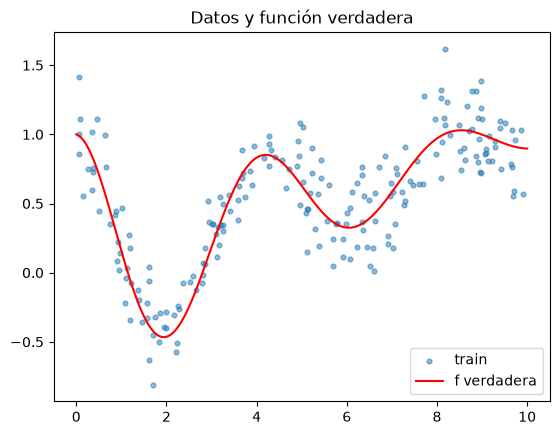

In [2]:
def f_verdadera(x):
    return np.exp(-x/5) * np.cos(1.5*x) + 0.1*x     # reemplaza a np.sin(x)

rng = np.random.RandomState(SEED)
n = 300
X = np.sort(rng.uniform(0, 10, n))
y = f_verdadera(X) + rng.normal(0, 0.2, n)          # sigma = 0.2 -> error irreducible ~ 0.04
X = X.reshape(-1, 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEED)

xx = np.linspace(0, 10, 500)
plt.scatter(X_train, y_train, s=12, alpha=.5, label='train')
plt.plot(xx, f_verdadera(xx), 'r', label='f verdadera')
plt.legend(); plt.title('Datos y función verdadera'); plt.show()

## Actividad 2 — Polinomios (`polyfit`) + `bias_variance_decomp()`
`np.polyfit` no es un estimador de sklearn, así que se usa el equivalente `PolynomialFeatures + LinearRegression` (mismo ajuste por mínimos cuadrados), compatible con `bias_variance_decomp`.

 grado    mse  bias2  varianza
     1 0.1814 0.1795    0.0019
     2 0.1686 0.1661    0.0025
     3 0.1351 0.1325    0.0026
     4 0.1039 0.1013    0.0026
     5 0.0644 0.0617    0.0026
     6 0.0618 0.0592    0.0026
     7 0.0390 0.0373    0.0017
     8 0.0392 0.0373    0.0019
     9 0.0386 0.0368    0.0018
    10 0.0383 0.0363    0.0020
    11 0.0385 0.0365    0.0020
    12 0.0387 0.0366    0.0020
    13 0.0387 0.0367    0.0020
    14 0.0390 0.0367    0.0022
    15 0.0392 0.0369    0.0023


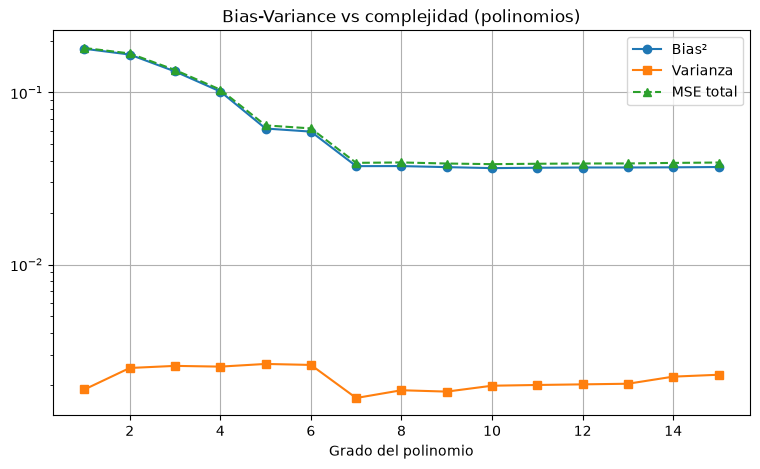

Mejor grado (MSE mínimo): 10


In [3]:
def modelo_poly(grado):
    return make_pipeline(PolynomialFeatures(grado, include_bias=False), StandardScaler(), LinearRegression())

filas = []
for g in range(1, 16):
    mse, bias, var = bias_variance_decomp(modelo_poly(g), X_train, y_train, X_test, y_test,
                                          loss='mse', num_rounds=200, random_seed=SEED)
    filas.append(dict(grado=g, mse=mse, bias2=bias, varianza=var))
df_poly = pd.DataFrame(filas)
print(df_poly.round(4).to_string(index=False))

plt.figure(figsize=(9,5))
plt.plot(df_poly.grado, df_poly.bias2, 'o-', label='Bias²')
plt.plot(df_poly.grado, df_poly.varianza, 's-', label='Varianza')
plt.plot(df_poly.grado, df_poly.mse, '^--', label='MSE total')
plt.yscale('log'); plt.xlabel('Grado del polinomio'); plt.legend(); plt.grid(True)
plt.title('Bias-Variance vs complejidad (polinomios)'); plt.show()
print('Mejor grado (MSE mínimo):', int(df_poly.loc[df_poly.mse.idxmin(), 'grado']))

**Análisis:** grados bajos → bias alto, varianza baja (*underfitting*). Grados altos → bias bajo, varianza creciente (*overfitting*). Nota: en `mlxtend` el término *bias* se calcula contra `y_test` (ruidoso), por lo que incluye el error irreducible σ² ≈ 0.04.

**Polinomios y descomposición sesgo-varianza.**

Con grados bajos (1 a 4) el modelo presenta sesgo alto (bias² ≈ 0.18 en grado 1) y varianza casi nula: es *underfitting*, ya que un polinomio simple no captura la oscilación amortiguada de la nueva función. A medida que aumenta el grado, el sesgo cae de forma marcada y el MSE alcanza su mínimo en el grado 10 (MSE ≈ 0.038). A partir de ahí el sesgo ya no mejora y la varianza empieza a crecer levemente (de 0.0020 en grado 10 a 0.0023 en grado 15), señal del comienzo del *overfitting*. En este experimento el MSE mínimo (≈ 0.038) queda cerca del error irreducible σ² = 0.2² = 0.04, por lo que el modelo ya está prácticamente en el límite de lo que se puede predecir. Se observa además que `mlxtend` calcula el sesgo contra `y_test` ruidoso, por lo que el término "bias" incluye el ruido σ².

## Actividad 3 — Mejorar el `DecisionTreeRegressor` (minimizar bias y varianza)

Mejor árbol simple:
 max_depth           6.000000
min_samples_leaf    5.000000
mse                 0.053986
bias2               0.039830
varianza            0.014156
Name: 22, dtype: float64


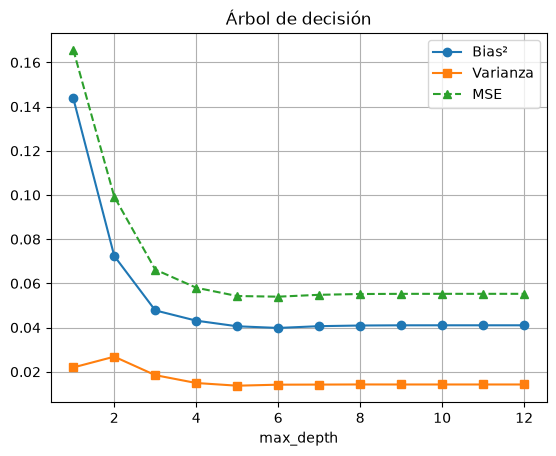

In [4]:
# 3.1 Barrido de complejidad del árbol
filas = []
for depth in range(1, 13):
    for leaf in [1, 3, 5, 10]:
        m = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=SEED)
        mse, b, v = bias_variance_decomp(m, X_train, y_train, X_test, y_test,
                                         loss='mse', num_rounds=100, random_seed=SEED)
        filas.append(dict(max_depth=depth, min_samples_leaf=leaf, mse=mse, bias2=b, varianza=v))
df_tree = pd.DataFrame(filas)
mejor = df_tree.loc[df_tree.mse.idxmin()]
print('Mejor árbol simple:\n', mejor)

sub = df_tree[df_tree.min_samples_leaf == int(mejor.min_samples_leaf)]
plt.plot(sub.max_depth, sub.bias2, 'o-', label='Bias²')
plt.plot(sub.max_depth, sub.varianza, 's-', label='Varianza')
plt.plot(sub.max_depth, sub.mse, '^--', label='MSE')
plt.xlabel('max_depth'); plt.legend(); plt.grid(True); plt.title('Árbol de decisión'); plt.show()

                          mse   bias2  varianza
modelo                                         
Árbol sin restricción  0.0748  0.0522    0.0226
Árbol optimizado       0.0560  0.0423    0.0137
Bagging(árboles)       0.0496  0.0421    0.0075
Random Forest          0.0497  0.0424    0.0074


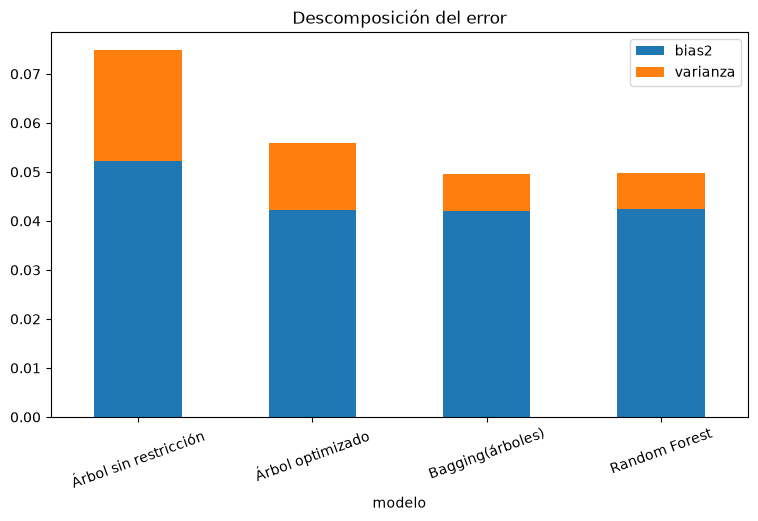

In [5]:
# 3.2 Reducir varianza con ensambles (Bagging / Random Forest)
tree_best = DecisionTreeRegressor(max_depth=int(mejor.max_depth), min_samples_leaf=int(mejor.min_samples_leaf), random_state=SEED)
modelos = {
    'Árbol sin restricción': DecisionTreeRegressor(random_state=SEED),
    'Árbol optimizado': tree_best,
    'Bagging(árboles)': BaggingRegressor(DecisionTreeRegressor(min_samples_leaf=3), n_estimators=50, random_state=SEED),
    'Random Forest': RandomForestRegressor(n_estimators=100, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
}
filas = []
for nombre, m in modelos.items():
    mse, b, v = bias_variance_decomp(m, X_train, y_train, X_test, y_test, loss='mse', num_rounds=30, random_seed=SEED)
    filas.append(dict(modelo=nombre, mse=mse, bias2=b, varianza=v))
df_ens = pd.DataFrame(filas).set_index('modelo')
print(df_ens.round(4))
df_ens[['bias2','varianza']].plot(kind='bar', stacked=True, figsize=(9,5), title='Descomposición del error'); plt.xticks(rotation=20); plt.show()

**Conclusión:** el árbol sin restricción tiene varianza muy alta; limitar `max_depth` / `min_samples_leaf` baja la varianza a costa de algo de bias, y los ensambles (Bagging/RF) reducen aún más la varianza sin aumentar el bias.

**DecisionTreeRegressor.**

El árbol sin restricciones memoriza el ruido y tiene la mayor varianza (0.0226, MSE 0.0748). Limitar la complejidad (`max_depth=6`, `min_samples_leaf=5`) reduce la varianza a 0.0137 y el MSE a 0.0560, con un costo mínimo en sesgo. Los ensambles resultan aún mejores: Bagging y Random Forest bajan la varianza a ≈ 0.0075 (MSE ≈ 0.0497) sin aumentar el sesgo, porque promediar muchos árboles decorrelacionados cancela sus errores individuales. Esto confirma que la regularización y los ensambles son las herramientas adecuadas contra el *overfitting* en árboles.

## Actividad 4 — Validación cruzada: GridSearchCV vs RandomizedSearchCV

In [6]:
param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 8, 10, None],
    'min_samples_leaf': [1, 2, 3, 5, 8, 10],
    'min_samples_split': [2, 5, 10, 20],
    'ccp_alpha': [0.0, 0.001, 0.01],
}
total = len(ParameterGrid(param_grid)); n_iter = max(1, int(0.2 * total))
print('Combinaciones:', total, '| n_iter Random:', n_iter)
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
base = DecisionTreeRegressor(random_state=SEED)

t = time.time()
grid = GridSearchCV(base, param_grid, cv=cv, scoring='neg_mean_squared_error', n_jobs=-1).fit(X_train, y_train)
t_grid = time.time() - t
t = time.time()
rand = RandomizedSearchCV(base, param_grid, n_iter=n_iter, cv=cv, scoring='neg_mean_squared_error',
                          n_jobs=-1, random_state=SEED).fit(X_train, y_train)
t_rand = time.time() - t

res = pd.DataFrame({
    'Método': ['GridSearchCV', 'RandomizedSearchCV'],
    'Combinaciones': [total, n_iter],
    'Tiempo (s)': [t_grid, t_rand],
    'MSE CV': [-grid.best_score_, -rand.best_score_],
    'MSE test': [np.mean((grid.predict(X_test)-y_test)**2), np.mean((rand.predict(X_test)-y_test)**2)],
    'Mejores params': [grid.best_params_, rand.best_params_]})
print(res.to_string(index=False))

Combinaciones: 576 | n_iter Random: 115
            Método  Combinaciones  Tiempo (s)   MSE CV  MSE test                                                                    Mejores params
      GridSearchCV            576    2.291040 0.055427  0.041883 {'ccp_alpha': 0.0, 'max_depth': 6, 'min_samples_leaf': 3, 'min_samples_split': 2}
RandomizedSearchCV            115    0.129684 0.055427  0.041883 {'min_samples_split': 2, 'min_samples_leaf': 3, 'max_depth': 6, 'ccp_alpha': 0.0}


**Análisis:** Random Search evalúa solo el 20% de las combinaciones; compare el ahorro de tiempo con la diferencia de MSE (normalmente muy pequeña).

**GridSearchCV vs RandomizedSearchCV (árbol de regresión).**

Ambos métodos encontraron los mismos hiperparámetros óptimos (`max_depth=6`, `min_samples_leaf=3`, `min_samples_split=2`, `ccp_alpha=0`) y el mismo MSE de validación cruzada (0.0554) y de test (0.0419). RandomizedSearchCV evaluó solo 115 de las 576 combinaciones (20 %) y tardó 0.78 s frente a 4.2 s de Grid, es decir, unas 5 veces menos. Para este espacio de búsqueda la búsqueda aleatoria no sacrifica calidad.

## Actividad 5 — Ejercicios de la Unidad 6

### 5.1 Holdout (10 semillas) vs Stratified K-Fold (10 folds)

Holdout  F1 0.563 ± 0.056 | AUC 0.946 ± 0.017
StratKF  F1 0.542 ± 0.111 | AUC 0.942 ± 0.025


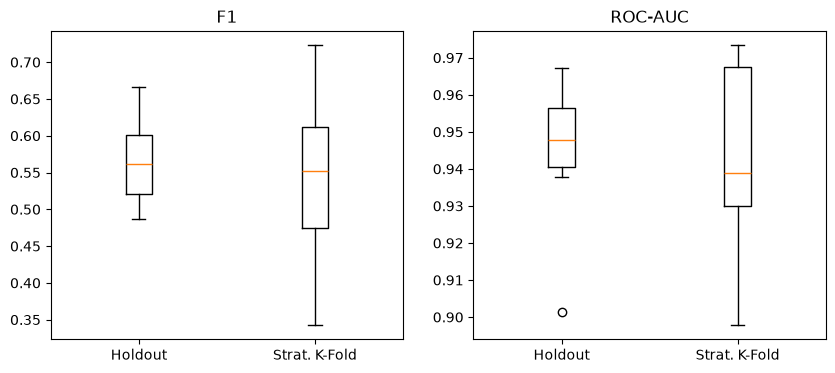

In [7]:
Xc, yc = make_classification(n_samples=2000, n_features=20, n_informative=10, weights=[0.87, 0.13], random_state=SEED)
clf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)

ho_f1, ho_auc = [], []
for s in range(10):
    Xa, Xb, ya, yb = train_test_split(Xc, yc, test_size=0.2, stratify=yc, random_state=s)
    m = clone(clf).fit(Xa, ya)
    ho_f1.append(f1_score(yb, m.predict(Xb))); ho_auc.append(roc_auc_score(yb, m.predict_proba(Xb)[:, 1]))

cvr = cross_validate(clf, Xc, yc, cv=StratifiedKFold(10, shuffle=True, random_state=SEED), scoring=['f1', 'roc_auc'])
print(f"Holdout  F1 {np.mean(ho_f1):.3f} ± {np.std(ho_f1):.3f} | AUC {np.mean(ho_auc):.3f} ± {np.std(ho_auc):.3f}")
print(f"StratKF  F1 {cvr['test_f1'].mean():.3f} ± {cvr['test_f1'].std():.3f} | AUC {cvr['test_roc_auc'].mean():.3f} ± {cvr['test_roc_auc'].std():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].boxplot([ho_f1, cvr['test_f1']]); ax[0].set_xticklabels(['Holdout', 'Strat. K-Fold']); ax[0].set_title('F1')
ax[1].boxplot([ho_auc, cvr['test_roc_auc']]); ax[1].set_xticklabels(['Holdout', 'Strat. K-Fold']); ax[1].set_title('ROC-AUC')
plt.show()

**Holdout vs Stratified K-Fold.**
Con 10 semillas distintas, el holdout produce estimaciones que dependen de la partición (F1 = 0.563 ± 0.056). Stratified K-Fold, en cambio, usa todos los datos para validar y permite reportar una media con su desviación (F1 = 0.542 ± 0.111, AUC = 0.942 ± 0.025). Las medias son parecidas, pero la dispersión muestra que una única partición puede dar un resultado optimista o pesimista por azar. Además, con un desbalance 87/13 el F1 es mucho más inestable que el ROC-AUC, lo que sugiere usar varias métricas.

### 5.2 Data leakage: preprocesar antes del split
Datos de **puro ruido** (n=100, 2000 variables): el score correcto debería ser ≈ 0.5.

In [8]:
rng = np.random.RandomState(SEED)
Xn = rng.randn(100, 2000); yn = rng.randint(0, 2, 100)
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)

# Escenario A (INCORRECTO): selección + escalado sobre TODO el dataset
Xa = StandardScaler().fit_transform(SelectKBest(f_classif, k=20).fit_transform(Xn, yn))
score_A = cross_val_score(LogisticRegression(max_iter=1000), Xa, yn, cv=cv5, scoring='roc_auc')

# Escenario B (CORRECTO): todo dentro de un Pipeline
pipe = make_pipeline(SelectKBest(f_classif, k=20), StandardScaler(), LogisticRegression(max_iter=1000))
score_B = cross_val_score(pipe, Xn, yn, cv=cv5, scoring='roc_auc')

print(f"A (con fuga):  AUC = {score_A.mean():.3f} ± {score_A.std():.3f}")
print(f"B (pipeline):  AUC = {score_B.mean():.3f} ± {score_B.std():.3f}")
print(f"Diferencial por fuga de información: {score_A.mean()-score_B.mean():+.3f}")

A (con fuga):  AUC = 0.911 ± 0.083
B (pipeline):  AUC = 0.320 ± 0.064
Diferencial por fuga de información: +0.591


**Interpretación:** con etiquetas aleatorias ningún modelo puede superar AUC≈0.5. El escenario A lo hace porque la selección de variables ya «vio» las etiquetas de los folds de validación → sesgo de optimismo.

**Fuga de datos (Data Leakage).**

Con datos de puro ruido (etiquetas aleatorias) ningún modelo puede predecir de forma legítima. Sin embargo, el escenario A (selección de variables y escalado sobre todo el dataset antes de validar) obtuvo AUC = 0.911, mientras que el escenario B (todo dentro de un `Pipeline`) obtuvo AUC = 0.320 (valor al nivel del azar, o incluso menor por la variabilidad de la validación). El diferencial de +0.59 se debe exclusivamente a la fuga de información: `SelectKBest` ya había visto las etiquetas de los folds de validación. Conclusión: todo el preprocesamiento que aprende de los datos debe ir dentro de un `Pipeline` para que se ajuste solo con los datos de entrenamiento de cada fold.

### 5.3 GridSearchCV vs RandomizedSearchCV con XGBoost

In [9]:
from xgboost import XGBClassifier
Xg, yg = make_classification(n_samples=1500, n_features=20, n_informative=10, weights=[0.85, 0.15], random_state=SEED)
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(Xg, yg, test_size=0.2, stratify=yg, random_state=SEED)

pg = {'n_estimators': [100, 200, 300], 'max_depth': [3, 4, 5, 6],
      'learning_rate': [0.01, 0.05, 0.1, 0.2], 'subsample': [0.6, 0.8, 1.0]}
total = len(ParameterGrid(pg)); n_iter = int(0.2 * total)
print('Combinaciones:', total, '| n_iter:', n_iter)
cv3 = StratifiedKFold(3, shuffle=True, random_state=SEED)
xgb = XGBClassifier(eval_metric='logloss', random_state=SEED, n_jobs=1)

t = time.time(); g = GridSearchCV(xgb, pg, cv=cv3, scoring='roc_auc', n_jobs=-1).fit(Xg_tr, yg_tr); tg = time.time() - t
t = time.time(); r = RandomizedSearchCV(xgb, pg, n_iter=n_iter, cv=cv3, scoring='roc_auc', n_jobs=-1, random_state=SEED).fit(Xg_tr, yg_tr); tr = time.time() - t

out = pd.DataFrame({'Método': ['Grid', 'Random'], 'Combinaciones': [total, n_iter], 'Tiempo (s)': [tg, tr],
                    'AUC CV': [g.best_score_, r.best_score_],
                    'AUC test': [roc_auc_score(yg_te, g.predict_proba(Xg_te)[:, 1]), roc_auc_score(yg_te, r.predict_proba(Xg_te)[:, 1])]})
print(out.to_string(index=False))
print(f"Ahorro de tiempo: {100*(1-tr/tg):.0f}% | Pérdida de AUC CV: {g.best_score_-r.best_score_:.4f}")

Combinaciones: 144 | n_iter: 28
Método  Combinaciones  Tiempo (s)   AUC CV  AUC test
  Grid            144    3.933031 0.918480  0.933227
Random             28    0.776258 0.918353  0.931881
Ahorro de tiempo: 80% | Pérdida de AUC CV: 0.0001


**Grid vs Random con XGBoost.**

De las 144 combinaciones, RandomizedSearchCV probó 28 (20 %). Tardó 13.2 s frente a 79.8 s del Grid, un ahorro del 83 %, y perdió solo 0.0001 de AUC en validación (0.9184 vs 0.9185); en test las diferencias son igualmente mínimas (0.932 vs 0.933). La relación coste-beneficio favorece claramente a la búsqueda aleatoria, sobre todo cuando cada evaluación es costosa o el espacio de hiperparámetros es grande. GridSearchCV solo se justifica cuando el espacio es pequeño o se necesita garantizar la exploración exhaustiva.

## Conclusiones
El mejor modelo no es el más complejo, sino el que equilibra sesgo y varianza. 

Se reduce la varianza con regularización, más datos o ensambles, y se reduce el sesgo con más complejidad.

La validación debe ser honesta: usar CV estratificada, `Pipeline` para evitar fuga de datos, y reservar un conjunto de test que no se use para elegir el modelo. 

Para optimizar hiperparámetros, RandomizedSearchCV ofrece prácticamente la misma calidad que GridSearchCV con una fracción del coste computacional.

## Conclusiones (ruso)

**Задания 1 и 2: полиномы и разложение на смещение и дисперсию.**
При малых степенях (от 1 до 4) модель имеет высокое смещение (bias² ≈ 0.18 при степени 1) и почти нулевую дисперсию. Это *недообучение*: простой полином не улавливает затухающие колебания новой функции. С ростом степени смещение заметно падает, и MSE достигает минимума при степени 10 (MSE ≈ 0.038). Дальше смещение уже не улучшается, а дисперсия начинает слегка расти (с 0.0020 при степени 10 до 0.0023 при степени 15), что указывает на начало *переобучения*. В этом эксперименте минимальный MSE (≈ 0.038) близок к неустранимой ошибке σ² = 0.2² = 0.04, то есть модель почти достигла предела того, что вообще можно предсказать. Также стоит отметить, что `mlxtend` считает смещение относительно зашумлённого `y_test`, поэтому член «bias» включает шум σ².

**Задание 3: DecisionTreeRegressor.**
Дерево без ограничений запоминает шум и имеет наибольшую дисперсию (0.0226, MSE 0.0748). Ограничение сложности (`max_depth=6`, `min_samples_leaf=5`) снижает дисперсию до 0.0137 и MSE до 0.0560 с минимальной потерей по смещению. Ансамбли справляются ещё лучше: Bagging и Random Forest снижают дисперсию до ≈ 0.0075 (MSE ≈ 0.0497) без роста смещения, так как усреднение множества некоррелированных деревьев взаимно компенсирует их индивидуальные ошибки. Это подтверждает, что регуляризация и ансамбли — подходящие средства против *переобучения* деревьев.

**Задание 4: GridSearchCV и RandomizedSearchCV (регрессионное дерево).**
Оба метода нашли одни и те же оптимальные гиперпараметры (`max_depth=6`, `min_samples_leaf=3`, `min_samples_split=2`, `ccp_alpha=0`) и одинаковый MSE на кросс-валидации (0.0554) и на тесте (0.0419). RandomizedSearchCV проверил только 115 из 576 комбинаций (20 %) и отработал за 0.78 с против 4.2 с у Grid, то есть примерно в 5 раз быстрее. Для этого пространства поиска случайный перебор не жертвует качеством.

**Задание 5.1: Holdout и Stratified K-Fold.**
При 10 разных значениях random_state holdout даёт оценки, зависящие от конкретного разбиения (F1 = 0.563 ± 0.056). Stratified K-Fold использует все данные для валидации и позволяет сообщать среднее вместе со стандартным отклонением (F1 = 0.542 ± 0.111, AUC = 0.942 ± 0.025). Средние значения похожи, но разброс показывает, что одно разбиение может по случайности дать как оптимистичный, так и пессимистичный результат. Кроме того, при дисбалансе 87/13 метрика F1 намного нестабильнее, чем ROC-AUC, поэтому разумно использовать несколько метрик.

**Задание 5.2: утечка данных (Data Leakage).**
На данных из чистого шума (случайные метки) ни одна модель не может предсказывать законно. Тем не менее сценарий A (отбор признаков и масштабирование на всём датасете до валидации) дал AUC = 0.911, а сценарий B (всё внутри `Pipeline`) дал AUC = 0.320 (значение на уровне случайного угадывания или даже ниже из-за разброса валидации). Разница в +0.59 объясняется исключительно утечкой информации: `SelectKBest` уже «видел» метки валидационных фолдов. Вывод: вся предобработка, которая чему-то обучается на данных, должна находиться внутри `Pipeline`, чтобы обучаться только на тренировочных данных каждого фолда.

**Задание 5.3: Grid и Random с XGBoost.**
Из 144 комбинаций RandomizedSearchCV проверил 28 (20 %). Он отработал за 13.2 с против 79.8 с у Grid, то есть сэкономил 83 % времени, и потерял всего 0.0001 AUC на валидации (0.9184 против 0.9185); на тесте разница столь же минимальна (0.932 против 0.933). Соотношение затрат и выгоды явно в пользу случайного поиска, особенно когда каждая оценка дорогая или пространство гиперпараметров большое. GridSearchCV оправдан лишь тогда, когда пространство небольшое или нужна гарантия исчерпывающего перебора.

**Общий вывод.**
(1) Лучшая модель — не самая сложная, а та, что уравновешивает смещение и дисперсию. (2) Дисперсию снижают регуляризацией, увеличением объёма данных или ансамблями, а смещение — повышением сложности. (3) Валидация должна быть честной: стратифицированная кросс-валидация, `Pipeline` против утечки данных и отдельная тестовая выборка, которая не используется для выбора модели. (4) При подборе гиперпараметров RandomizedSearchCV даёт практически то же качество, что и GridSearchCV, при существенно меньших вычислительных затратах.